# **Twelfth Night Dialogue Analysis. Visualization 3: What Do They Talk About?**
**CTS 2000 Group Project · Visualization 3 (word frequency) · Soumya's part**

**What this notebook does.** Visualizations 1 and 2 count lines and connections. This one looks at the **words** characters use. We compare what Orsino's court and Olivia's household talk about, and how Viola talks while she is disguised as Cesario.

### Research Questions
1. **RQ1.** How do conversations change from Act 1 to Act 5? Do they get more chaotic and then settle?
2. **RQ2.** How separate are Orsino's court and Olivia's household? Who connects them?
3. **RQ3.** What changes if Viola and Cesario are treated as two people? What did the disguise let her do?

This notebook answers **RQ2** (Sections 3.2 and 3.4) and **RQ3** (Sections 3.3 and 3.4). RQ1 is answered in Visualizations 1 and 2.

### How this Notebook uses Course Concepts
| Step | What we do | From the course |
|---|---|---|
| Cleaning the speeches | tokenize, remove stopwords, lemmatize (done in `data_cleaning.ipynb`) | Week 6, 6-2 |
| Filtering the table | picking rows by speaker, persona, act and scene | Week 6, 6-1 pandas |
| Counting words | `Counter` and `most_common` | Week 6, 6-2 |
| Comparing groups of different sizes | relative frequency (uses per 1,000 words), ignoring rare words | Week 7, 7-1 |
| Bar charts | `plt.bar` and `plt.barh` | Week 6, 6-2 and Week 8, 8-2 |

## **1. Data**
We use `data/twelfth_night_speeches.csv`, made in `data_cleaning.ipynb` from the Folger edition of the play. It has one row per speech: **926 speeches and 2,634 lines**, the same as the Folger XML used in Visualization 2.

*In one sentence:* every speech in the play, with who said it, where, and a cleaned list of its words.

In [1]:
import pandas as pd
from collections import Counter
import matplotlib.pyplot as plt

speeches = pd.read_csv('data/twelfth_night_speeches.csv')

# short speeches like "I will." have no words left after cleaning, so they are empty
speeches['clean_text'] = speeches['clean_text'].fillna('')

print(len(speeches), 'speeches,', speeches['lines'].sum(), 'lines')
speeches.head()

926 speeches, 2634 lines


,act,scene,speaker,lines,text,persona,clean_text
0,1,1,ORSINO,15,"If music be the food of love, play on.\nGive m...",ORSINO,music food love play give excess surfeit appet...
1,1,1,CURIO,1,"Will you go hunt, my lord?",CURIO,go hunt lord
2,1,1,ORSINO,1,"What, Curio?",ORSINO,curio
3,1,1,CURIO,1,The hart.,CURIO,hart
4,1,1,ORSINO,7,"Why, so I do, the noblest that I have.\nO, whe...",ORSINO,noble mine eye see olivia first methought purg...


**The columns:** `act` and `scene` say where the speech is · `speaker` is the name in the text (Feste is `FOOL`, Sir Toby is `TOBY`) · `lines` is how many lines of the play it takes · `text` is the speech itself · `persona` is the same as `speaker`, except that Viola's speeches say `CESARIO` while she is disguised · `clean_text` is the speech after cleaning.

Here is the first speech of the play, before and after cleaning:

In [2]:
first = speeches.loc[0]
print(first['speaker'], '- Act', first['act'], 'Scene', first['scene'])
print()
print(first['text'])
print()
print('Cleaned:', first['clean_text'])

ORSINO - Act 1 Scene 1

If music be the food of love, play on.
Give me excess of it, that, surfeiting,
The appetite may sicken and so die.
That strain again! It had a dying fall.
O, it came o'er my ear like the sweet sound
That breathes upon a bank of violets,
Stealing and giving odor. Enough; no more.
'Tis not so sweet now as it was before.
O spirit of love, how quick and fresh art thou,
That, notwithstanding thy capacity
Receiveth as the sea, naught enters there,
Of what validity and pitch soe'er,
But falls into abatement and low price
Even in a minute. So full of shapes is fancy
That it alone is high fantastical.

Cleaned: music food love play give excess surfeit appetite may sicken die strain die fall come ear like sweet sound breathe bank violet steal give odor enough sweet spirit love quick fresh notwithstanding capacity receiveth sea naught enters validity pitch fall abatement low price even minute full shape fancy alone high fantastical


## **2. Method**
1. **Fix two lemmatizer mistakes.** The WordNet lemmatizer turned "alas" into "ala" and "us" into "u" (it thinks they are plurals), so we change them back before counting.
2. **Count words** for a group of speeches with `Counter`.
3. **Use uses per 1,000 words** instead of raw counts, because some groups speak much more than others.
4. **Find the words that make two groups different:** for every word, its rate in group A minus its rate in group B. We ignore words used fewer than 8 times in total, so rare words don't take over the chart (7-1).

*In one sentence:* we count each word and divide by how much the group speaks, so groups of different sizes can be compared fairly.

In [3]:
fixes = {'ala': 'alas', 'u': 'us'}

def get_words(df):
    """All the cleaned words in a set of speeches, as one list."""
    words = ' '.join(df['clean_text']).split()
    return [fixes.get(w, w) for w in words]

def per_1000(counts, total):
    """Turn raw counts into uses per 1,000 words."""
    return {word: count / total * 1000 for word, count in counts.items()}

def most_different(counts_a, counts_b, min_count=8):
    """Rate in A minus rate in B for every word used at least min_count times in total."""
    rate_a = per_1000(counts_a, sum(counts_a.values()))
    rate_b = per_1000(counts_b, sum(counts_b.values()))
    rows = []
    for word in set(counts_a) | set(counts_b):
        if counts_a[word] + counts_b[word] >= min_count:
            rows.append({'word': word, 'A': counts_a[word], 'B': counts_b[word],
                         'difference': rate_a.get(word, 0) - rate_b.get(word, 0)})
    return pd.DataFrame(rows)

# same colours as the networks in Visualization 2
COURT_COLOUR = '#e0a800'
HOUSEHOLD_COLOUR = '#3b6fb6'
NEITHER_COLOUR = '#9bb5a0' 

## **3. Results**
### 3.1 The whole play

Total words: 8365
Different words: 2426


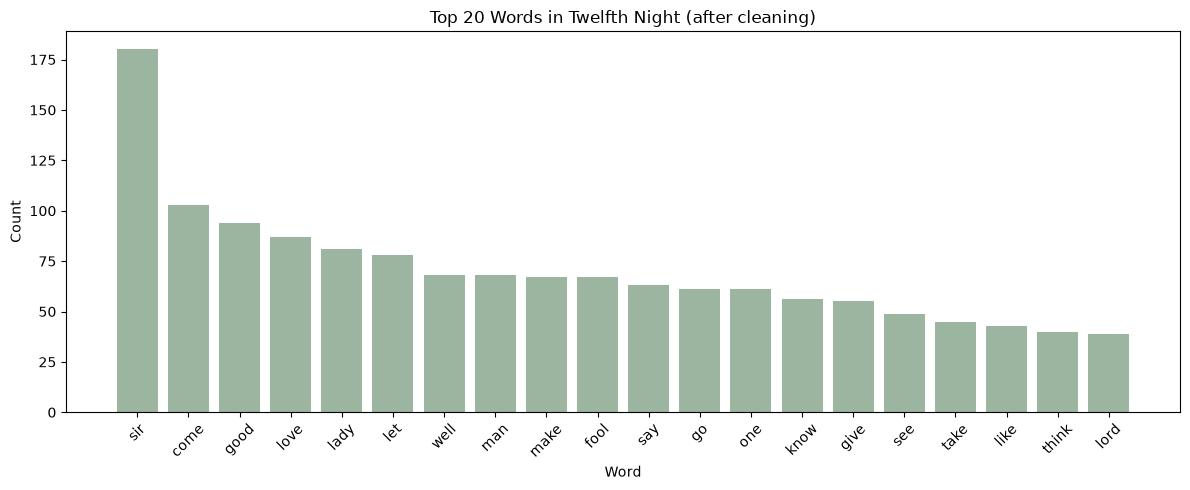

In [4]:
all_counts = Counter(get_words(speeches))
print('Total words:', sum(all_counts.values()))
print('Different words:', len(all_counts))

words, counts = zip(*all_counts.most_common(20))
plt.figure(figsize=(12, 5))
plt.bar(words, counts, color=NEITHER_COLOUR)
plt.title('Top 20 Words in Twelfth Night (after cleaning)')
plt.xlabel('Word')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

*In one sentence:* across the whole play the top words are mostly everyday words (sir, come, good, let, well), so we need to compare groups of characters to learn anything.

### 3.2 RQ2: Orsino's court vs. Olivia's household
We use the same groups as the network notebook (Visualization 2):
- **Court:** Orsino, Curio, Valentine
- **Household:** Olivia, Maria, Malvolio, Sir Toby, Sir Andrew, Fabian

Feste and Viola/Cesario are in neither group, because they move between both. Section 3.4 comes back to them.

Court words: 778
Household words: 4411


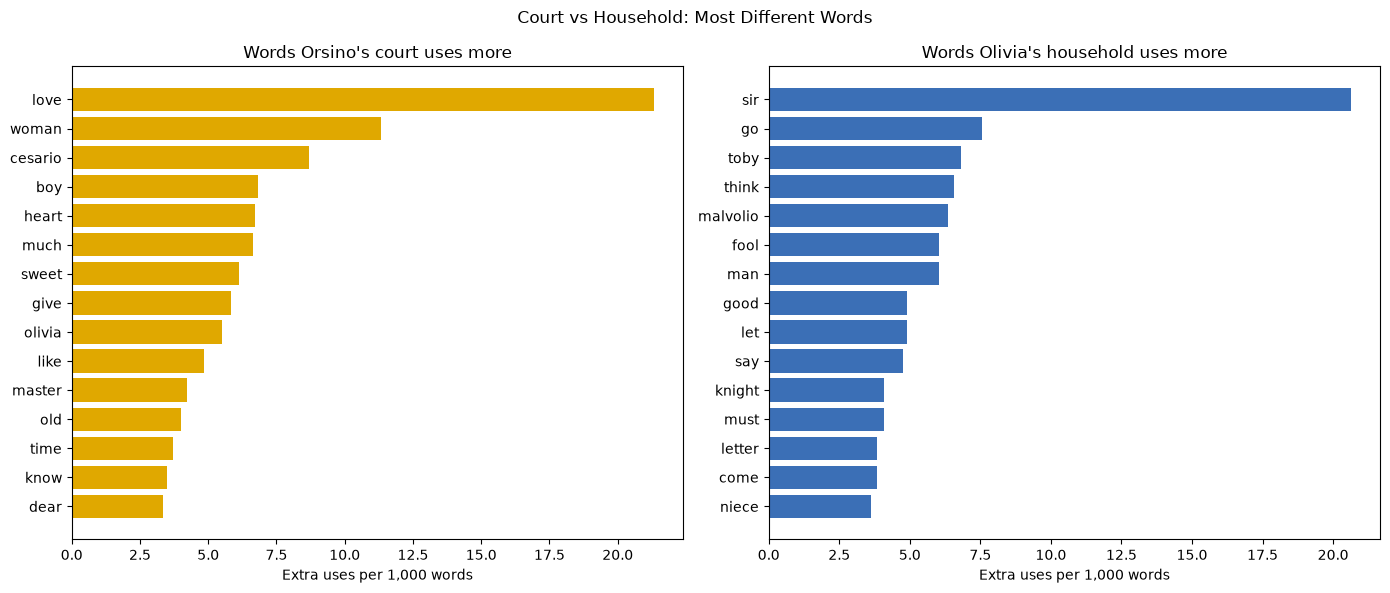

Court uses more:
   word  court  household  difference
   love     21         25        21.3
  woman      9          1        11.3
cesario      8          7         8.7
    boy      6          4         6.8
  heart      7         10         6.7
   much      8         16         6.7
  sweet      6          7         6.1
   give     10         31         5.8

Household uses more:
    word  court  household  difference
     sir      0         91       -20.6
      go      1         39        -7.6
    toby      0         30        -6.8
   think      0         29        -6.6
malvolio      0         28        -6.3
    fool      2         38        -6.0
     man      2         38        -6.0
    good      5         50        -4.9


In [5]:
court = ['ORSINO', 'CURIO', 'VALENTINE']
household = ['OLIVIA', 'MARIA', 'MALVOLIO', 'TOBY', 'ANDREW', 'FABIAN']

court_counts = Counter(get_words(speeches[speeches['speaker'].isin(court)]))
household_counts = Counter(get_words(speeches[speeches['speaker'].isin(household)]))
print('Court words:', sum(court_counts.values()))
print('Household words:', sum(household_counts.values()))

compare = most_different(court_counts, household_counts).rename(columns={'A': 'court', 'B': 'household'})

# when two words have the same difference, sort them alphabetically so the result is the same every time
more_court = compare.sort_values(['difference', 'word'], ascending=[False, True]).head(15)
more_household = compare.sort_values(['difference', 'word'], ascending=[True, True]).head(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
# reverse so the biggest bar is at the top
axes[0].barh(more_court['word'][::-1], more_court['difference'][::-1], color=COURT_COLOUR)
axes[0].set_title("Words Orsino's court uses more")
axes[0].set_xlabel('Extra uses per 1,000 words')
axes[1].barh(more_household['word'][::-1], -more_household['difference'][::-1], color=HOUSEHOLD_COLOUR)
axes[1].set_title("Words Olivia's household uses more")
axes[1].set_xlabel('Extra uses per 1,000 words')
plt.suptitle('Court vs Household: Most Different Words')
plt.tight_layout()
plt.savefig('figures/court_vs_household_words.png', dpi=200)
plt.show()

print('Court uses more:')
print(more_court.head(8).round(1).to_string(index=False))
print()
print('Household uses more:')
print(more_household.head(8).round(1).to_string(index=False))

**What this shows:** the court's words are about feeling: love, woman, heart, sweet, dear. "Love" is about 27 uses per 1,000 words in the court and under 6 in the household. The court's list also has "Cesario" and "boy", the names Orsino uses for Viola in disguise. The household's words are about rank, its own members and the joke on Malvolio: sir, knight, niece, Toby, Malvolio, fool and letter (the fake letter).

*In one sentence:* the two worlds talk about different things: the court about love, the household about rank and its trick on Malvolio.

### 3.3 RQ3: Cesario with Orsino vs. Cesario with Olivia
Using the `persona` column, we take only the speeches Viola gives **as Cesario**, and split them by who she is sent to:
- **With Orsino:** Act 1 Scene 4, Act 2 Scene 4
- **With Olivia:** Act 1 Scene 5, Act 3 Scene 1

Cesario with Orsino: 136 words
Cesario with Olivia: 404 words


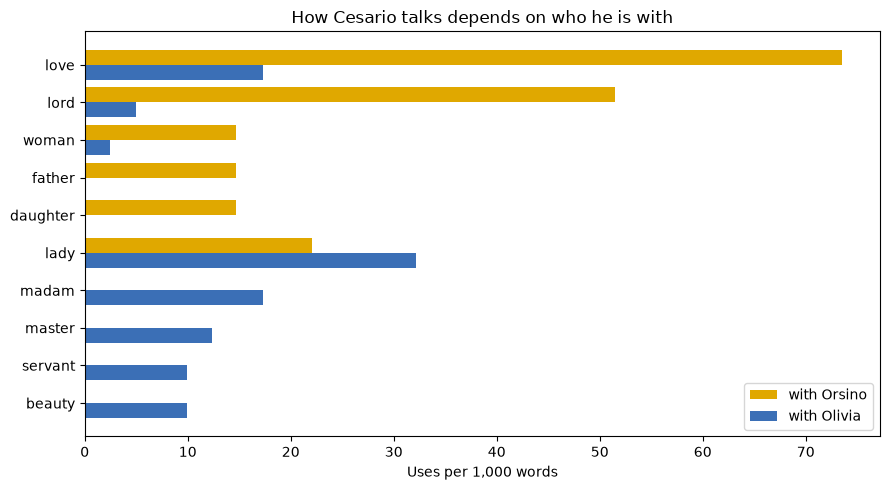

,with Orsino (count),"with Orsino (per 1,000)",with Olivia (count),"with Olivia (per 1,000)"
love,10,73.5,7,17.3
lord,7,51.5,2,5.0
woman,2,14.7,1,2.5
father,2,14.7,0,0.0
daughter,2,14.7,0,0.0
lady,3,22.1,13,32.2
madam,0,0.0,7,17.3
master,0,0.0,5,12.4
servant,0,0.0,4,9.9
beauty,0,0.0,4,9.9


In [6]:
cesario = speeches[speeches['persona'] == 'CESARIO']

def in_scenes(df, scene_list):
    keep = [(act, scene) in scene_list for act, scene in zip(df['act'], df['scene'])]
    return df[keep]

orsino_counts = Counter(get_words(in_scenes(cesario, [(1, 4), (2, 4)])))
olivia_counts = Counter(get_words(in_scenes(cesario, [(1, 5), (3, 1)])))
orsino_rate = per_1000(orsino_counts, sum(orsino_counts.values()))
olivia_rate = per_1000(olivia_counts, sum(olivia_counts.values()))
print('Cesario with Orsino:', sum(orsino_counts.values()), 'words')
print('Cesario with Olivia:', sum(olivia_counts.values()), 'words')

chosen = ['love', 'lord', 'woman', 'father', 'daughter', 'lady', 'madam', 'master', 'servant', 'beauty']
y = range(len(chosen))
plt.figure(figsize=(9, 5))
plt.barh([i - 0.2 for i in y], [orsino_rate.get(w, 0) for w in chosen], height=0.4, color=COURT_COLOUR, label='with Orsino')
plt.barh([i + 0.2 for i in y], [olivia_rate.get(w, 0) for w in chosen], height=0.4, color=HOUSEHOLD_COLOUR, label='with Olivia')
plt.yticks(list(y), chosen)
plt.gca().invert_yaxis()
plt.xlabel('Uses per 1,000 words')
plt.title('How Cesario talks depends on who he is with')
plt.legend()
plt.tight_layout()
plt.savefig('figures/viola_orsino_vs_olivia.png', dpi=200)
plt.show()

pd.DataFrame({'with Orsino (count)': [orsino_counts[w] for w in chosen],
              'with Orsino (per 1,000)': [round(orsino_rate.get(w, 0), 1) for w in chosen],
              'with Olivia (count)': [olivia_counts[w] for w in chosen],
              'with Olivia (per 1,000)': [round(olivia_rate.get(w, 0), 1) for w in chosen]}, index=chosen)

**What this shows:** with Orsino, Cesario says "love" about 74 times per 1,000 words, over 4 times more than with Olivia (about 17), and also says lord, woman, father and daughter. With Olivia, Cesario uses the words of a servant on an errand: lady, madam, master, servant, beauty, and never says father or daughter.

*In one sentence:* the disguise is not one voice. Cesario talks about love with Orsino and plays the polite messenger with Olivia.

### 3.4 RQ2 and RQ3: who talks like both worlds?
The network notebook found that Viola/Cesario and Feste are the bridges between the two groups. Here we check their **words**: we take the 15 words the court uses most (compared to the household) and the 15 words the household uses most (from 3.2), and count how often each character uses them, per 1,000 words.

Cesario, Feste and Sebastian were **not** used to make the two word lists, so their scores are a fair test. Orsino, Olivia and Toby are shown only for reference: they helped make the lists, so they will look like their own group.

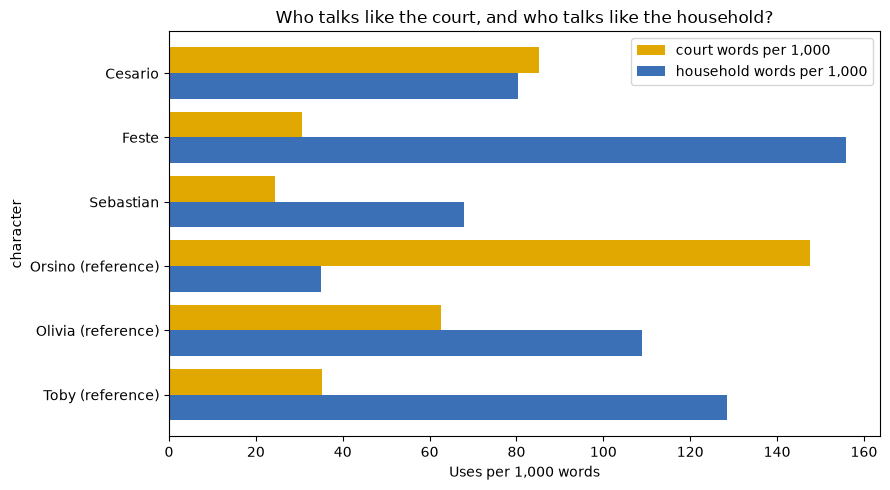

,words,"court words per 1,000","household words per 1,000"
character,,,
Cesario,797,85.3,80.3
Feste,1142,30.6,155.9
Sebastian,412,24.3,68.0
Orsino (reference),712,147.5,35.1
Olivia (reference),974,62.6,108.8
Toby (reference),1160,35.3,128.4


In [7]:
court_words = list(more_court['word'])
household_words = list(more_household['word'])

people = {'Cesario': speeches[speeches['persona'] == 'CESARIO'],
          'Feste': speeches[speeches['speaker'] == 'FOOL'],
          'Sebastian': speeches[speeches['speaker'] == 'SEBASTIAN'],
          'Orsino (reference)': speeches[speeches['speaker'] == 'ORSINO'],
          'Olivia (reference)': speeches[speeches['speaker'] == 'OLIVIA'],
          'Toby (reference)': speeches[speeches['speaker'] == 'TOBY']}

rows = []
for name, df in people.items():
    counts = Counter(get_words(df))
    total = sum(counts.values())
    rows.append({'character': name, 'words': total,
                 'court words per 1,000': round(sum(counts[w] for w in court_words) / total * 1000, 1),
                 'household words per 1,000': round(sum(counts[w] for w in household_words) / total * 1000, 1)})
both = pd.DataFrame(rows).set_index('character')

both[['court words per 1,000', 'household words per 1,000']].plot.barh(
    color=[COURT_COLOUR, HOUSEHOLD_COLOUR], figsize=(9, 5), width=0.8)
plt.gca().invert_yaxis()
plt.xlabel('Uses per 1,000 words')
plt.title('Who talks like the court, and who talks like the household?')
plt.tight_layout()
plt.savefig('figures/who_talks_like_both.png', dpi=200)
plt.show()
both

**What this shows:** Cesario uses court words and household words almost equally (about 85 and 80 per 1,000). Feste also moves between both groups, but he talks like the household (about 156 household words per 1,000 against 31 court words). Sebastian leans to the household too.

*In one sentence:* Feste visits both worlds but speaks the household's language, while Cesario is the only character who speaks both.

## **4. What this shows**
- **RQ2:** the court and the household are separate in their words, not just in who shares the stage. The court talks about love, the household about rank and the joke on Malvolio.
- **RQ3:** treating Cesario on his own shows that the disguise changes how Viola speaks depending on who she is with: love with Orsino, the polite servant with Olivia.
- **RQ2 + RQ3:** Cesario is the only character whose words are balanced between the two worlds. Together with Visualization 2 (Cesario is the main bridge on stage), this suggests the disguise is what lets Viola connect the two groups.

*In one sentence:* the disguise lets Viola speak the language of both worlds, which is why she, as Cesario, is the one who connects them.

## **5. Limitations and dead ends**
- **Small numbers.** The court only says about 800 words after cleaning (Orsino does most of the talking), and Cesario has only 136 words in the Orsino scenes, so one or two speeches can change the results a lot.
- **Splitting by scene is rough.** In Act 1 Scene 5 and Act 3 Scene 1, Cesario also talks to Maria, Feste and Sir Toby, so some of those words are not said to Olivia. Act 3 Scene 4 and Act 5 Scene 1 are left out because many characters are on stage.
- **We chose the groups.** We follow the network notebook and put Olivia in her household. In our first version Olivia was in the court group, and the numbers changed ("love" was 57 court vs 14 household in raw counts), so how we draw the groups shapes the answer.
- **Word lists from the same people.** In 3.4, Orsino, Olivia and Toby helped make the word lists, so only Cesario, Feste and Sebastian are a fair test.
- **Lemmatizing is made for modern English.** We fixed "alas" and "us", but old spellings may still be lemmatized wrongly.
- **Counts don't show meaning.** "Love" can be serious (Orsino) or a joke (Sir Toby), and counting treats them the same. We use the numbers to point us to passages to read, not instead of reading them.
- **Dead end:** counting the whole play (3.1) gave mostly everyday words and told us little, which is why we compare groups.